# 02 - Clustering: K-Means, DBSCAN e Agglomerative

Este notebook utiliza a classe `Clustering` de `src/clustering.py`, seguindo o padrão de clustering bivariado em pares de features.

In [133]:
import os
try:
    os.chdir("projeto_hector")
except FileNotFoundError:
    pass

from joblib import load, dump
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.clustering import Clustering, silhouette_scorer_func

## 1. Carregar os Dados

Carregamos os dados pré-processados e divididos no notebook anterior.

In [134]:
# Carregar os dados salvos do notebook de preparação
X_train = load("data/01_X_train")
X_valid = load("data/01_X_valid")
X_test = load("data/01_X_test")
y_train = load("data/01_y_train")
y_valid = load("data/01_y_valid")
y_test = load("data/01_y_test")
feature_names = load("data/01_feature_names")
df_processado = load("data/01_df_processado")

print(f"X_train: {X_train.shape}")
print(f"X_valid: {X_valid.shape}")
print(f"X_test: {X_test.shape}")

X_train: (131, 3)
X_valid: (44, 3)
X_test: (44, 3)


In [135]:
# Reconstruir DataFrames com nomes de colunas para a classe Clustering
# A classe Clustering espera colunas nomeadas e uma coluna 'classe'

df_train = pd.DataFrame(X_train, columns=feature_names)
df_train["classe"] = y_train.values

df_valid = pd.DataFrame(X_valid, columns=feature_names)
df_valid["classe"] = y_valid.values

df_test = pd.DataFrame(X_test, columns=feature_names)
df_test["classe"] = y_test.values

print(f"df_train shape: {df_train.shape}")
print(f"df_valid shape: {df_valid.shape}")
print(f"df_test shape: {df_test.shape}")
df_train.head()

df_train shape: (131, 4)
df_valid shape: (44, 4)
df_test shape: (44, 4)


,Grupo_1,Grupo_2,Grupo_3,classe
0,0.832760,1.728856,-1.001037,0
1,-0.539623,0.109994,-0.759331,0
2,-1.225815,0.045239,-0.034214,0
3,-0.005918,1.728856,-0.034214,0
4,-1.378302,-0.731814,-0.759331,0


## 2. Seleção de Pares (Bivariada)

Clustering bivariado (trabalha com 2 variáveis por vez), então precisamos selecionar pares.

In [136]:
from itertools import combinations

# Selecionar pares de features para testar

# Como temos 37 features, testar todos os pares levaria muito tempo
# Selecionamos um subconjunto representativo (1 feature por gene)
features_selecionadas = [
    "GSTP1_AA", "MGMT_AA", "VDR_TC", "BCL2_CA",
    "CASP9_GA", "NKX3_TT", "CASP3_CC", "PTEN_CG",
    "AKT1_CC", "PI3K_GG", "AMACR_GA", "MTOR_TT"
]

# Teste com todas os pares de features:
todas_features = df_train.columns
todas_features = todas_features.drop("classe")
todas_features = list(todas_features)

# Análise agrupada com 3 grupos:
grupos_features = ["Grupo_1", "Grupo_2", "Grupo_3"]

# Análise a partir das frequencias:
features_freq = [
    "GSTP1", "MGMT", "VDR", "BCL2",
    "CASP9", "NKX3", "CASP3", "PTEN",
    "AKT1", "PI3K", "AMACR", "MTOR"
]

# Gerar combinações de pares (mudar aqui qual lista usar)
pares = list(combinations(grupos_features, 2))
print(f"Total de pares para testar: {len(pares)}")
print(f"Primeiros 5 pares: {pares[:5]}")

Total de pares para testar: 3
Primeiros 5 pares: [('Grupo_1', 'Grupo_2'), ('Grupo_1', 'Grupo_3'), ('Grupo_2', 'Grupo_3')]


----------


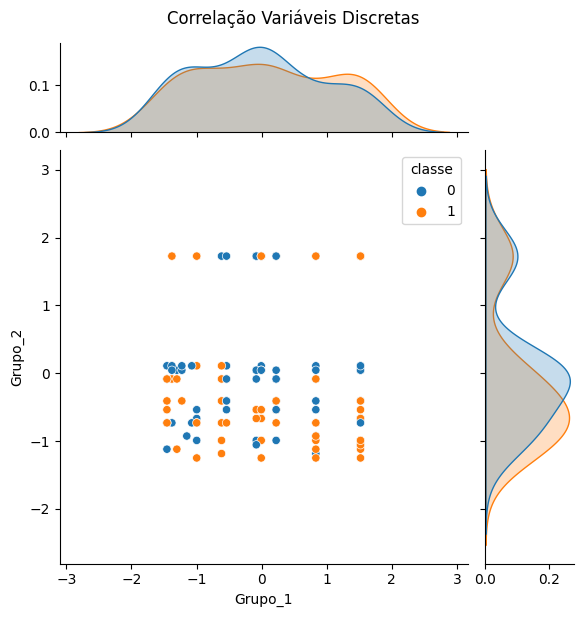

----------


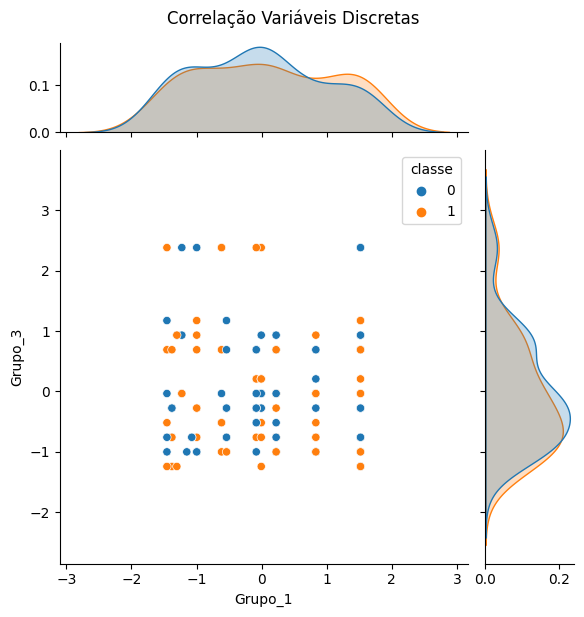

----------


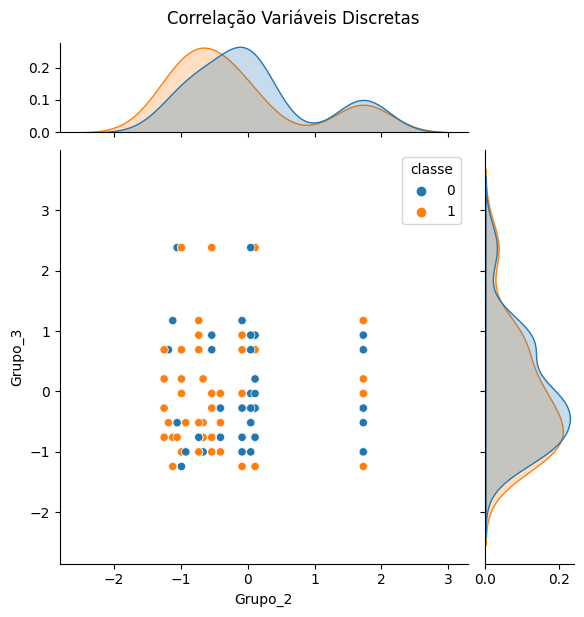

In [137]:
# Gráfico das variáveis que conseguem separar as classes dos dados
# Teste com os 5 primeiros pares
for idx, (c1, c2) in enumerate(pares[:5]):
    print("-" * 10)
    p = sns.jointplot(
        x=c1,
        y=c2,
        hue="classe",
        height=6,
        ratio=4,
        marginal_ticks=True,
        data=df_train,
    )
    p.fig.suptitle("Correlação Variáveis Discretas", y=1.02)
    p.set_axis_labels(xlabel=c1, ylabel=c2)
    plt.show()

### 2.5. Aplicando PCA

O treino com bivariadas baseadas nos genótipos ficou muito ruim, decidi testar utilizando os valores de PCA.

Testei o K-means, ficou **PÉSSIMO**

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=4) # 4 componentes para gerar combinação de pares
colunas_pca = ["PC1", "PC2", "PC3", "PC4"]

# Como vamos usar um PCA, vamos testar com todas as features
X_train_all = df_train[todas_features].copy()
X_train_pca = pca.fit_transform(X_train_all)
df_train_pca = pd.DataFrame(X_train_pca, columns=colunas_pca)
df_train_pca["classe"] = df_train["classe"].values


X_test_all = df_test[todas_features].copy()
X_test_pca = pca.fit_transform(X_test_all)
df_test_pca = pd.DataFrame(X_test_pca, columns=colunas_pca)
df_test_pca["classe"] = df_test["classe"].values

X_valid_all = df_valid[todas_features].copy()
X_valid_pca = pca.fit_transform(X_valid_all)
df_valid_pca = pd.DataFrame(X_valid_pca, columns=colunas_pca)
df_valid_pca["classe"] = df_valid["classe"].values


# PCA com features selecionadas
X_train_selected = df_train[features_selecionadas].copy()
X_test_selected = df_test[features_selecionadas].copy()
X_valid_selected = df_valid[features_selecionadas].copy()

# Criar pares com os componentes (6 combinações)
pares_pca = list(combinations(colunas_pca, 2))

df_train_pca.head()


---
## 3. K-Means Clustering

Aplicando o algoritmo K-Means aos pares de features.

### 3.1 Busca do Melhor Par de Variáveis (Cross-Validation)

Iteramos sobre os pares utilizando `cross_validation(print_metricas=False)`.

In [138]:
nome_modelo = "kmeans"
resultados_kmeans = []

# Adaptando para o PCA
#pares = pares_pca
#df_train = df_train_pca
#df_test = df_test_pca
#df_valid = df_valid_pca


for i, j in pares:
    cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
    _, metricas = cluster.cross_validation(print_metricas=False)
    ss, chs, dbs, ari, ami = metricas
    resultados_kmeans.append({
        "c1": i, "c2": j,
        "Silhouette": ss, "CHS": chs, "DBS": dbs,
        "ARI": ari, "AMI": ami
    })

df_resultados_kmeans = pd.DataFrame(resultados_kmeans)
df_resultados_kmeans = df_resultados_kmeans.sort_values("Silhouette", ascending=False)
print("=== TOP 5 PARES K-MEANS (por Silhouette Score) ===")
display(df_resultados_kmeans.head())

print("\nGuia de interpretação:")
print("  Silhouette Score:     Quanto MAIOR melhor (-1 a 1)")
print("  Calinski-Harabasz:    Quanto MAIOR melhor")
print("  Davies-Bouldin:       Quanto MENOR melhor (>= 0)")
print("  Adjusted Rand Index:  Quanto MAIOR melhor (-1 a 1)")
print("  Adjusted Mutual Info: Quanto MAIOR melhor (0 a 1)")

=== TOP 5 PARES K-MEANS (por Silhouette Score) ===


,c1,c2,Silhouette,CHS,DBS,ARI,AMI
2,Grupo_2,Grupo_3,0.572,186.772,0.665,-0.007,-0.007
0,Grupo_1,Grupo_2,0.497,195.399,0.629,-0.008,-0.008
1,Grupo_1,Grupo_3,0.452,135.211,0.734,-0.005,-0.005



Guia de interpretação:
  Silhouette Score:     Quanto MAIOR melhor (-1 a 1)
  Calinski-Harabasz:    Quanto MAIOR melhor
  Davies-Bouldin:       Quanto MENOR melhor (>= 0)
  Adjusted Rand Index:  Quanto MAIOR melhor (-1 a 1)
  Adjusted Mutual Info: Quanto MAIOR melhor (0 a 1)


In [139]:
# Selecionando as melhores combinações de variáveis com base nas métricas
# de avaliação de clustering
display(df_resultados_kmeans["Silhouette"].nlargest(1))
display(df_resultados_kmeans["CHS"].nlargest(1))
display(df_resultados_kmeans["DBS"].nsmallest(1))
display(df_resultados_kmeans["ARI"].nlargest(1))
display(df_resultados_kmeans["AMI"].nlargest(1))

2    0.572
Name: Silhouette, dtype: float64

0    195.399
Name: CHS, dtype: float64

0    0.629
Name: DBS, dtype: float64

1   -0.005
Name: ARI, dtype: float64

1   -0.005
Name: AMI, dtype: float64

### 3.2 Treinar com o Melhor Par

Selecionamos o melhor par e rodamos `cross_validation` com `print_metricas=True`.

Melhor par K-Means: Grupo_2 x Grupo_3
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 3, 'init': 'k-means++', 'n_init': 10}
Silhouette Score Médio (CV): 0.5554

Silhouette Score -> 0.572
Calinski Harabasz Score -> 186.772
Davies Bouldin Score -> 0.665
Adjusted Rand Score -> -0.007
Adjusted Mutual Info Score -> -0.007


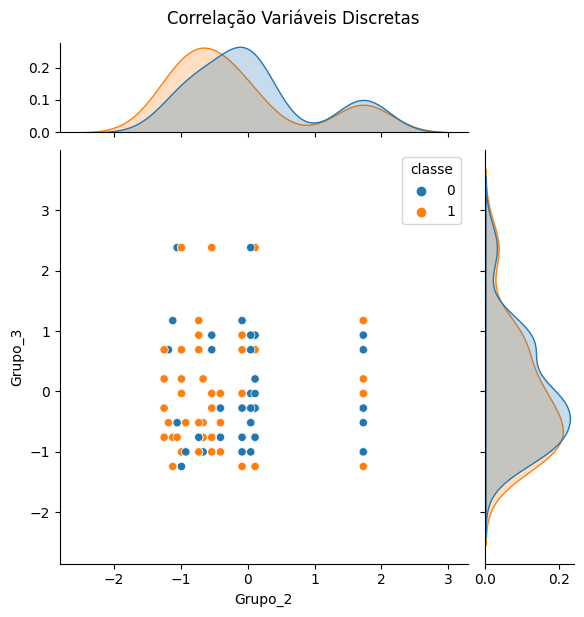

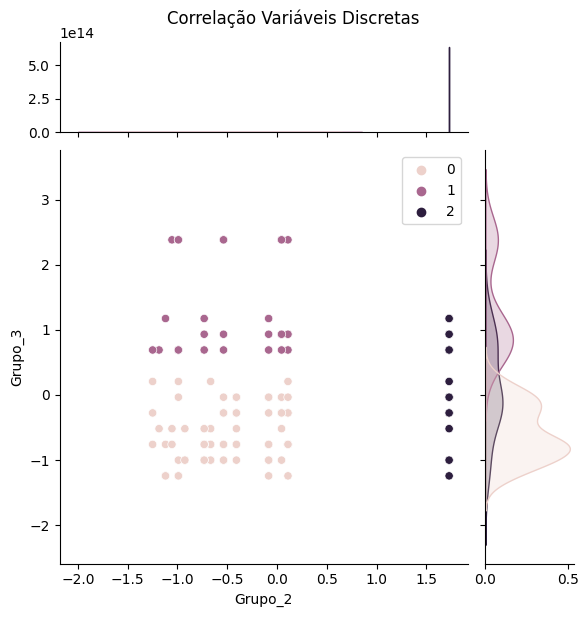

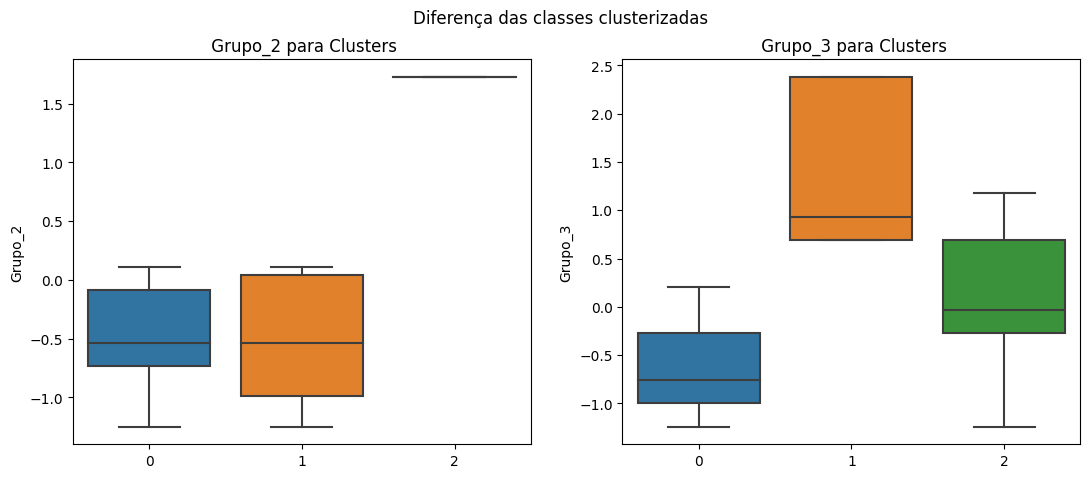

In [140]:
# Selecionar o melhor par
# O melhor par foi o 3 (index [0])
best_pair_km = df_resultados_kmeans.iloc[0]
i, j = best_pair_km["c1"], best_pair_km["c2"]
print(f"Melhor par K-Means: {i} x {j}")

# Treinar e visualizar com o melhor par
cluster = Clustering(c1=i, c2=j, df=df_train, modelo="kmeans")
cluster.cross_validation()

### 3.3 Teste de Consistência K-Means

Utilizamos `testar_modelo()` para verificar se os clusters são consistentes entre o treino e a validação.

In [141]:
# Obter os melhores parâmetros (rodando novamente sem print)
cluster = Clustering(c1=i, c2=j, df=df_train, modelo="kmeans")
labels, _ = cluster.cross_validation(print_metricas=False)

# Nota: Para testar_modelo, precisamos obter os best_params
# A classe Clustering não expõe best_params diretamente, então
# testamos com parâmetros padrão encontrados
best_param_km = {"n_clusters": 2, "init": "k-means++", "n_init": "auto"}

resultado = cluster.testar_modelo(best_param=best_param_km, df_test=df_valid)
print(f"\nClusters consistentes? {resultado}")

 RESULTADOS DA ANÁLISE DE COMPARAÇÃO DE CLUSTERS
Frequências Esperadas na Validação (Treino): 
[15.11450382 28.88549618]
Frequências Observadas na Validação:
       [20 24]
--------------------------------------------------
Estatística Qui-Quadrado (χ²): 2.4054
p-valor:                        0.1209
--------------------------------------------------
Conclusão: Não rejeitamos H0. A distribuição dos clusters na validação É IGUAL à do treino (p > 0.05).
--------------------------------------------------
Adjusted Rand Index (ARI) entre modelo de Treino e modelo da Validação: 0.0526 (ARI próximo de 1.0 indica que a partição geométrica gerada é virtualmente idêntica)

Clusters consistentes? True


---
## 4. DBSCAN Clustering

Aplicando o algoritmo DBSCAN.

In [142]:
nome_modelo = "dbscan"
resultados_dbscan = []

for i, j in pares:
    try:
        cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
        _, metricas = cluster.cross_validation(print_metricas=False)
        ss, chs, dbs, ari, ami = metricas
        resultados_dbscan.append({
            "c1": i, "c2": j,
            "Silhouette": ss, "CHS": chs, "DBS": dbs,
            "ARI": ari, "AMI": ami
        })
    except Exception as e:
        pass  # DBSCAN pode falhar em alguns pares

df_resultados_dbscan = pd.DataFrame(resultados_dbscan)
df_resultados_dbscan = df_resultados_dbscan.sort_values("Silhouette", ascending=False)
print("=== TOP 5 PARES DBSCAN (por Silhouette Score) ===")
display(df_resultados_dbscan.head())

print("\nGuia de interpretação:")
print("  Silhouette Score:     Quanto MAIOR melhor (-1 a 1)")
print("  Calinski-Harabasz:    Quanto MAIOR melhor")
print("  Davies-Bouldin:       Quanto MENOR melhor (>= 0)")
print("  Adjusted Rand Index:  Quanto MAIOR melhor (-1 a 1)")
print("  Adjusted Mutual Info: Quanto MAIOR melhor (0 a 1)")

=== TOP 5 PARES DBSCAN (por Silhouette Score) ===


,c1,c2,Silhouette,CHS,DBS,ARI,AMI
2,Grupo_2,Grupo_3,0.563,125.033,0.456,-0.006,-0.020
0,Grupo_1,Grupo_2,0.387,97.260,0.734,-0.007,-0.011
1,Grupo_1,Grupo_3,0.343,64.421,0.725,-0.006,-0.019



Guia de interpretação:
  Silhouette Score:     Quanto MAIOR melhor (-1 a 1)
  Calinski-Harabasz:    Quanto MAIOR melhor
  Davies-Bouldin:       Quanto MENOR melhor (>= 0)
  Adjusted Rand Index:  Quanto MAIOR melhor (-1 a 1)
  Adjusted Mutual Info: Quanto MAIOR melhor (0 a 1)


In [143]:
# Selecionando as melhores combinações de variáveis com base nas métricas
# de avaliação de clustering
display(df_resultados_dbscan["Silhouette"].nlargest(1))
display(df_resultados_dbscan["CHS"].nlargest(1))
display(df_resultados_dbscan["DBS"].nsmallest(1))
display(df_resultados_dbscan["ARI"].nlargest(1))
display(df_resultados_dbscan["AMI"].nlargest(1))

2    0.563
Name: Silhouette, dtype: float64

2    125.033
Name: CHS, dtype: float64

2    0.456
Name: DBS, dtype: float64

2   -0.006
Name: ARI, dtype: float64

0   -0.011
Name: AMI, dtype: float64

Melhor par DBSCAN: Grupo_2 x Grupo_3
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.5, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.3421

Silhouette Score -> 0.563
Calinski Harabasz Score -> 125.033
Davies Bouldin Score -> 0.456
Adjusted Rand Score -> -0.006
Adjusted Mutual Info Score -> -0.02


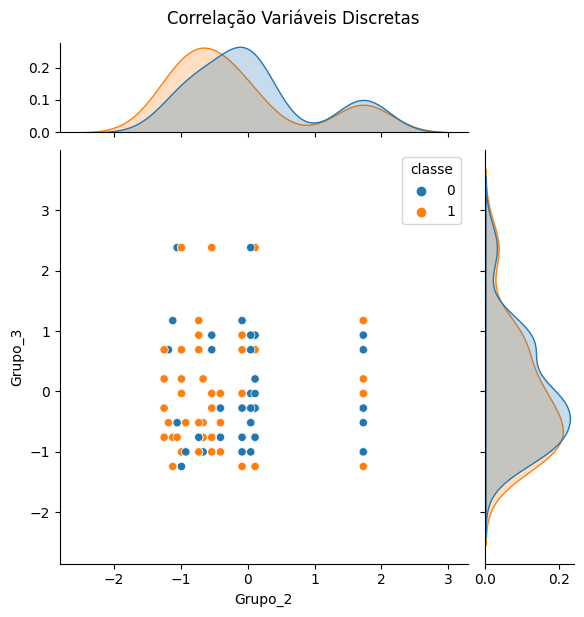

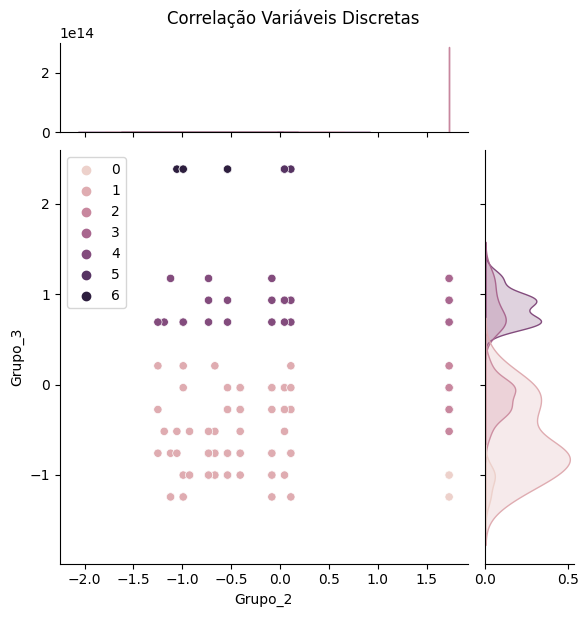

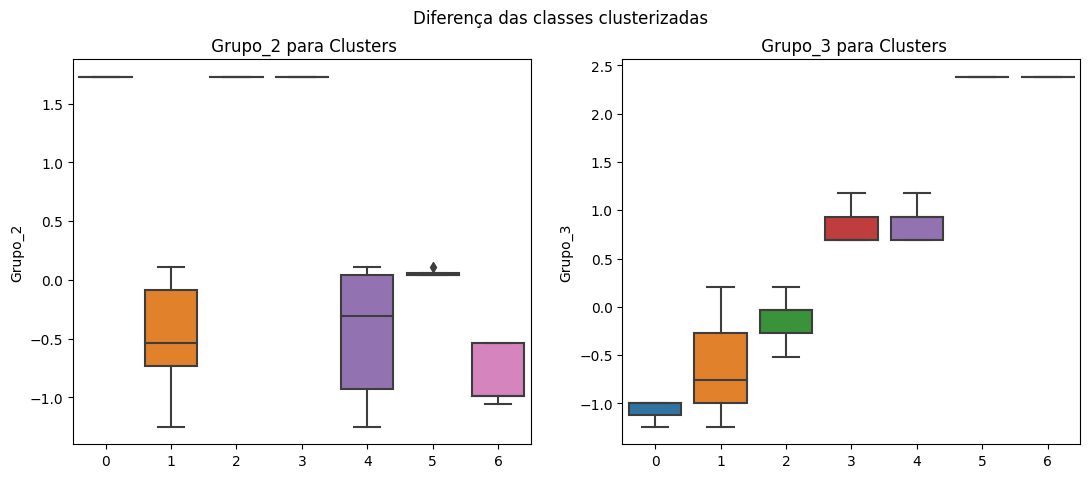

In [144]:
if not df_resultados_dbscan.empty:
    best_pair_db = df_resultados_dbscan.iloc[0]
    i, j = best_pair_db["c1"], best_pair_db["c2"]
    print(f"Melhor par DBSCAN: {i} x {j}")

    cluster = Clustering(c1=i, c2=j, df=df_train, modelo="dbscan")
    cluster.cross_validation()
else:
    print("DBSCAN não encontrou clusters válidos em nenhum par.")

In [145]:
if not df_resultados_dbscan.empty:
    best_param_db = {"eps": 0.5, "min_samples": 5, "metric": "euclidean"}
    resultado_db = cluster.testar_modelo(best_param=best_param_db, df_test=df_valid)
    print(f"\nClusters consistentes? {resultado_db}")

 RESULTADOS DA COMPARAÇÃO DE CLUSTERS (DBSCAN)
Clusters identificados no Treino:       
[-1  0  1  2]
Frequências Esperadas na Validação:     
[ 1.68 32.58  8.06  1.68]
Frequências Observadas na Validação:    
[ 2 29 11  2]
-------------------------------------------------------
Estatística Qui-Quadrado (χ²): 1.5873
p-valor:                        0.6623
-------------------------------------------------------
Conclusão: Não rejeitamos H0. A distribuição dos clusters
na validação É IGUAL à do treino (p > 0.05).
-------------------------------------------------------
Adjusted Rand Index (ARI) entre predição e DBSCAN direto na Validação: 0.3294

Clusters consistentes? True


---
## 5. Agglomerative Clustering

Aplicando o algoritmo Agglomerative Clustering.

In [146]:
nome_modelo = "agglomerative"
resultados_agg = []

for i, j in pares:
    try:
        cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
        _, metricas = cluster.cross_validation(print_metricas=False)
        ss, chs, dbs, ari, ami = metricas
        resultados_agg.append({
            "c1": i, "c2": j,
            "Silhouette": ss, "CHS": chs, "DBS": dbs,
            "ARI": ari, "AMI": ami
        })
    except Exception:
        pass

df_resultados_agg = pd.DataFrame(resultados_agg)
df_resultados_agg = df_resultados_agg.sort_values("Silhouette", ascending=False)
print("=== TOP 5 PARES AGGLOMERATIVE (por Silhouette Score) ===")
display(df_resultados_agg.head())

print("\nGuia de interpretação:")
print("  Silhouette Score:     Quanto MAIOR melhor (-1 a 1)")
print("  Calinski-Harabasz:    Quanto MAIOR melhor")
print("  Davies-Bouldin:       Quanto MENOR melhor (>= 0)")
print("  Adjusted Rand Index:  Quanto MAIOR melhor (-1 a 1)")
print("  Adjusted Mutual Info: Quanto MAIOR melhor (0 a 1)")

=== TOP 5 PARES AGGLOMERATIVE (por Silhouette Score) ===


,c1,c2,Silhouette,CHS,DBS,ARI,AMI
2,Grupo_2,Grupo_3,0.572,186.772,0.665,-0.007,-0.007
0,Grupo_1,Grupo_2,0.522,170.432,0.651,-0.009,-0.009
1,Grupo_1,Grupo_3,0.456,133.953,0.730,-0.005,-0.006



Guia de interpretação:
  Silhouette Score:     Quanto MAIOR melhor (-1 a 1)
  Calinski-Harabasz:    Quanto MAIOR melhor
  Davies-Bouldin:       Quanto MENOR melhor (>= 0)
  Adjusted Rand Index:  Quanto MAIOR melhor (-1 a 1)
  Adjusted Mutual Info: Quanto MAIOR melhor (0 a 1)


In [147]:
# Selecionando as melhores combinações de variáveis com base nas métricas
# de avaliação de clustering
display(df_resultados_agg["Silhouette"].nlargest(1))
display(df_resultados_agg["CHS"].nlargest(1))
display(df_resultados_agg["DBS"].nsmallest(1))
display(df_resultados_agg["ARI"].nlargest(1))
display(df_resultados_agg["AMI"].nlargest(1))

2    0.572
Name: Silhouette, dtype: float64

2    186.772
Name: CHS, dtype: float64

0    0.651
Name: DBS, dtype: float64

1   -0.005
Name: ARI, dtype: float64

1   -0.006
Name: AMI, dtype: float64

Melhor par Agglomerative: Grupo_2 x Grupo_3
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 3, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.5632

Silhouette Score -> 0.572
Calinski Harabasz Score -> 186.772
Davies Bouldin Score -> 0.665
Adjusted Rand Score -> -0.007
Adjusted Mutual Info Score -> -0.007


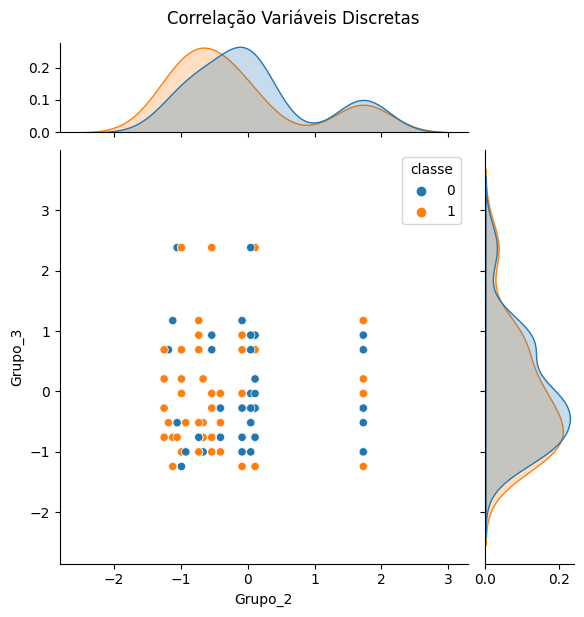

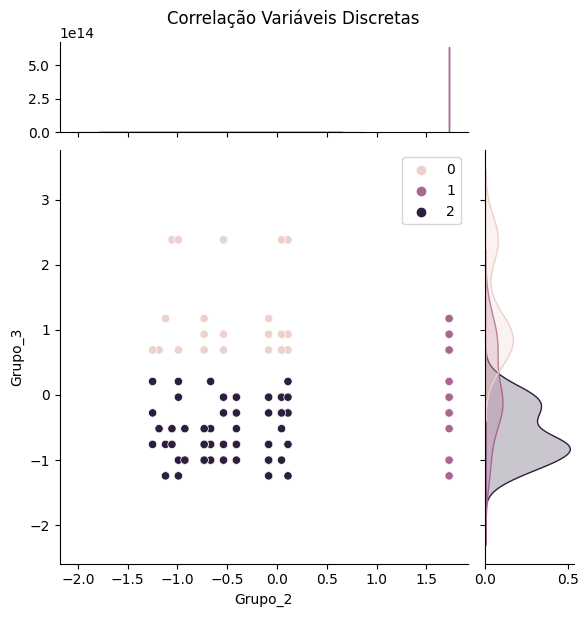

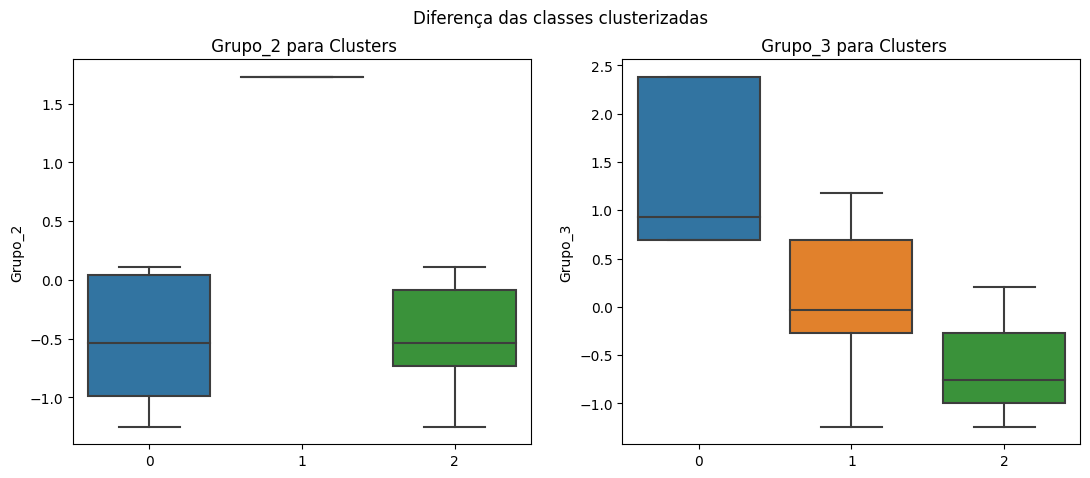

In [148]:
best_pair_agg = df_resultados_agg.iloc[0]
i, j = best_pair_agg["c1"], best_pair_agg["c2"]
print(f"Melhor par Agglomerative: {i} x {j}")

cluster = Clustering(c1=i, c2=j, df=df_train, modelo="agglomerative")
cluster.cross_validation()

In [149]:
best_param_agg = {"n_clusters": 2, "metric": "euclidean", "linkage": "ward"}
resultado_agg = cluster.testar_modelo(best_param=best_param_agg, df_test=df_valid)
print(f"\nClusters consistentes? {resultado_agg}")

 RESULTADOS DA COMPARAÇÃO (AGGLOMERATIVE CLUSTERING)
Clusters no Treino:                  
[0 1]
Frequências Esperadas na Validação:  
[35.6  8.4]
Frequências Observadas na Validação:  
[32 12]
------------------------------------------------------------
Estatística Qui-Quadrado (χ²): 1.9107
p-valor:                        0.1669
------------------------------------------------------------
Conclusão: Não rejeitamos H0. A distribuição dos clusters na validação É IGUAL à do treino (p > 0.05).
------------------------------------------------------------
Adjusted Rand Index (ARI) entre projeção e agrupamento direto: 1.0000

Clusters consistentes? True


---
## 6. Comparação dos Algoritmos

Comparamos os melhores resultados de cada algoritmo.

In [152]:
# Comparação dos melhores resultados de cada algoritmo
comparacao = pd.DataFrame([
    {"Algoritmo": "K-Means",
     "Par": f"{df_resultados_kmeans.iloc[0]['c1']} x {df_resultados_kmeans.iloc[0]['c2']}",
     **{k: df_resultados_kmeans.iloc[0][k] for k in ["Silhouette", "CHS", "DBS", "ARI", "AMI"]}},
])

if not df_resultados_dbscan.empty:
    comparacao = pd.concat([comparacao, pd.DataFrame([{
        "Algoritmo": "DBSCAN",
        "Par": f"{df_resultados_dbscan.iloc[0]['c1']} x {df_resultados_dbscan.iloc[0]['c2']}",
        **{k: df_resultados_dbscan.iloc[0][k] for k in ["Silhouette", "CHS", "DBS", "ARI", "AMI"]}
    }])])

comparacao = pd.concat([comparacao, pd.DataFrame([{
    "Algoritmo": "Agglomerative",
    "Par": f"{df_resultados_agg.iloc[0]['c1']} x {df_resultados_agg.iloc[0]['c2']}",
    **{k: df_resultados_agg.iloc[0][k] for k in ["Silhouette", "CHS", "DBS", "ARI", "AMI"]}
}])])

print("=" * 70)
print(" COMPARAÇÃO DOS ALGORITMOS DE CLUSTERING")
print("=" * 70)
display(comparacao)

print("\nGuia de interpretação:")
print("  Silhouette Score:     Quanto MAIOR melhor (-1 a 1)")
print("  Calinski-Harabasz:    Quanto MAIOR melhor")
print("  Davies-Bouldin:       Quanto MENOR melhor (>= 0)")
print("  Adjusted Rand Index:  Quanto MAIOR melhor (-1 a 1)")
print("  Adjusted Mutual Info: Quanto MAIOR melhor (0 a 1)")

 COMPARAÇÃO DOS ALGORITMOS DE CLUSTERING


,Algoritmo,Par,Silhouette,CHS,DBS,ARI,AMI
0,K-Means,Grupo_2 x Grupo_3,0.572,186.772,0.665,-0.007,-0.007
0,DBSCAN,Grupo_2 x Grupo_3,0.563,125.033,0.456,-0.006,-0.020
0,Agglomerative,Grupo_2 x Grupo_3,0.572,186.772,0.665,-0.007,-0.007



Guia de interpretação:
  Silhouette Score:     Quanto MAIOR melhor (-1 a 1)
  Calinski-Harabasz:    Quanto MAIOR melhor
  Davies-Bouldin:       Quanto MENOR melhor (>= 0)
  Adjusted Rand Index:  Quanto MAIOR melhor (-1 a 1)
  Adjusted Mutual Info: Quanto MAIOR melhor (0 a 1)


## 7. Salvar Resultados

In [153]:
os.makedirs("data", exist_ok=True)
dump(df_resultados_kmeans, "data/02_resultados_kmeans")
dump(df_resultados_dbscan, "data/02_resultados_dbscan")
dump(df_resultados_agg, "data/02_resultados_agg")
dump(comparacao, "data/02_comparacao_clustering")
print("✅ Resultados salvos com sucesso!")

✅ Resultados salvos com sucesso!
